# SAC

优化目标在原基础上加入了熵：
$\pi^* = \arg\max_\pi
\mathbb{E}_{(s_t,a_t)\sim\pi}
\Bigl[
r(s_t,a_t) + \alpha H\!\bigl(\pi(\cdot|s_t)\bigr)
\Bigr]$


对于策略函数，就是要最大化$V(s_t)\\$
$V(s_t)=\mathbb{E}_{a_t \sim \pi}[Q(s_t, a_t)-\alpha log\pi(a_t|s_t)]=\mathbb{E}_{a_t \sim \pi}[Q(s_t,a_t)]+H(\pi(\cdot|s_t))\\$
所以损失函数为:$L_{\pi}(\theta)\\=(1/N)\sum^N_1(-\alpha H(\pi(\cdot|s_t))-min_{j=1,2}Q_{\omega_j}(s_i,a_i))\\=(1/N)\sum^N_1(\alpha log\pi_{\theta}(a_i|s_i)-min_{j=1,2}Q_{\omega_j}(s_i,a_i))$

对于Q网络，依然是时序差分更新：$Q(s_t,a_t)=r(s_t, a_t)+\gamma \mathbb{E}_{s_{t+1}}[V(s_{t+1})]\\$
所以损失函数为: $L_Q(\omega)=\mathbb{E}_{(s_t,a_t,r_t,s_{t+1})\sim R}[0.5(Q_{\omega}(s_t, a_t)-(r_t+\gamma V_{\omega^-}(s_{t+1})))^2]$

为了抑制$Q$值的过高估计，每次都选择目标网络和Q网络中最低的状态动作价值

Import modules

In [1]:
import random
import gym
import numpy as np
from tqdm import tqdm
import torch
import torch.nn.functional as F
from torch.distributions import Normal
import matplotlib.pyplot as plt
import rl_utils
np.bool8 = np.bool

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/var/folders/qn/n_1307qj75q0sdzx36m_mn040000gn/T/ipykernel_39871/3210283112.py:10: DeprecationWarning: `np.bool` is a deprecated alias for the builtin `bool`. To silence this warning, use `bool` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.bool_` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  np.bool8 = np.bool


Define policy network class and critic network class

In [2]:
class PolicyNetContinuous(torch.nn.Module):
    def __init__(self, state_dim, hidden_dim, action_dim, action_bound):
        super(PolicyNetContinuous, self).__init__()
        self.fc1 = torch.nn.Linear(state_dim, hidden_dim)
        self.fc_mu = torch.nn.Linear(hidden_dim, action_dim)
        self.fc_std = torch.nn.Linear(hidden_dim, action_dim)
        self.action_bound = action_bound

    def forward(self, obs):
        x = F.relu(self.fc1(obs))
        # 计算输出分布
        mu = self.fc_mu(x)
        std = F.softplus(self.fc_std(x))
        dist = Normal(mu, std)
        # 重参数化采样
        normal_sample = dist.rsample() # Pi(a|s)
        log_prob = dist.log_prob(normal_sample) # log(Pi(a|s))
        action = torch.tanh(normal_sample) # 限制动作在[-1,1]之间
        # 修正概率分布
        log_prob = log_prob - torch.log(1 - torch.tanh(action).pow(2) + 1e-7)
        action = action * self.action_bound
        return action, log_prob
    
class CriticNet(torch.nn.Module):
    def __init__(self, state_dim, hidden_dim, action_dim):
        super(CriticNet, self).__init__()
        self.fc1 = torch.nn.Linear(state_dim+action_dim, hidden_dim)
        self.fc2 = torch.nn.Linear(hidden_dim, hidden_dim)
        self.fc_out = torch.nn.Linear(hidden_dim, 1)
    
    def forward(self, obs, a):
        x = torch.concatenate([obs, a], dim=1)
        x = F.relu(self.fc1(x))
        x = F.relu((self.fc2(x)))
        return self.fc_out(x)

Define SAC policy

In [3]:
class SACAgent:
    def __init__(self, state_dim, hidden_dim, action_dim, action_bound, 
                 actor_lr, critic_lr, alpha_lr, target_entropy, tau, gamma, 
                 device):
        self.actor = PolicyNetContinuous(state_dim, hidden_dim, action_dim, action_bound)
        self.critic_1 = CriticNet(state_dim, hidden_dim, action_dim).to(device)
        self.critic_2 = CriticNet(state_dim, hidden_dim, action_dim).to(device)
        self.target_1 = CriticNet(state_dim, hidden_dim, action_dim).to(device)
        self.target_2 = CriticNet(state_dim, hidden_dim, action_dim).to(device)

        # 令目标Q网络的初始参数和Q网络一样
        self.target_1.load_state_dict(self.critic_1.state_dict())
        self.target_2.load_state_dict(self.critic_2.state_dict())
        self.actor_optimizer = torch.optim.Adam(self.actor.parameters(),
                                                lr=actor_lr)
        self.critic_1_optimizer = torch.optim.Adam(self.critic_1.parameters(),
                                                   lr=critic_lr)
        self.critic_2_optimizer = torch.optim.Adam(self.critic_2.parameters(),
                                                   lr=critic_lr)       
        # 自动温度调整机制， 调节所需熵的程度
        self.log_alpha = torch.tensor(np.log(0.01), dtype=torch.float)
        self.log_alpha.requires_grad = True  # 可以对alpha求梯度
        self.log_alpha_optimizer = torch.optim.Adam([self.log_alpha], lr=alpha_lr)
        self.target_entropy = target_entropy  # 目标熵的大小
        self.gamma = gamma
        self.tau = tau
        self.device = device

    def take_action(self, obs):
        obs = torch.tensor([obs], dtype=torch.float).to(self.device)
        action = self.actor(obs)[0]
        return [action.item()]
    
    def update(self, transition_dict):
        states = torch.tensor(transition_dict['states'],
                              dtype=torch.float).to(self.device)
        actions = torch.tensor(transition_dict['actions'],
                               dtype=torch.float).view(-1, 1).to(self.device)
        rewards = torch.tensor(transition_dict['rewards'],
                               dtype=torch.float).view(-1, 1).to(self.device)
        next_states = torch.tensor(transition_dict['next_states'],
                                   dtype=torch.float).to(self.device)
        dones = torch.tensor(transition_dict['dones'],
                             dtype=torch.float).view(-1, 1).to(self.device)
        # trick 
        rewards = (rewards + 8.0) / 8.0

        # 更新Q网络
        td_target = self.calc_target(rewards, next_states, dones) #用目标网络计算V(s')
        critic_1_loss = torch.mean(F.mse_loss(self.critic_1(states, actions), td_target.detach()))
        critic_2_loss = torch.mean(F.mse_loss(self.critic_2(states, actions), td_target.detach()))
        self.critic_1_optimizer.zero_grad()
        critic_1_loss.backward()
        self.critic_1_optimizer.step()
        self.critic_2_optimizer.zero_grad()
        critic_2_loss.backward()
        self.critic_2_optimizer.step()
        # 更新策略
        rsample_action, log_prob = self.actor(states)
        entropy = -log_prob
        q_value_1 = self.critic_1(states, rsample_action)
        q_value_2 = self.critic_2(states, rsample_action)
        actor_loss = torch.mean(-self.log_alpha.exp() * entropy - torch.min(q_value_1, q_value_2))
        self.actor_optimizer.zero_grad()
        actor_loss.backward()
        self.actor_optimizer.step()
        # 更新alpha
        alpha_loss = torch.mean(
            (entropy - self.target_entropy).detach() * self.log_alpha.exp())
        self.log_alpha_optimizer.zero_grad()
        alpha_loss.backward()
        self.log_alpha_optimizer.step()
        # 更新目标网络, soft update
        self.soft_update(self.critic_1, self.target_1)
        self.soft_update(self.critic_2, self.target_2)        
    
    def calc_target(self, reward, next_obs, dones):
        next_actions, log_prob = self.actor(next_obs)
        entropy = -log_prob # -log(Pi(a'|s'))
        q1_value = self.target_1(next_obs, next_actions) # Q1'(s',a')
        q2_value = self.target_2(next_obs, next_actions) # Q2'(s',a')
        q_value = torch.min(q1_value, q2_value)
        next_value = q_value + self.log_alpha.exp() * entropy
        td_target = reward + self.gamma * next_value * (1 - dones)
        return td_target

    def soft_update(self, net, target_net):
        for param_target, param in zip(target_net.parameters(),
                                       net.parameters()):
            param_target.data.copy_(param_target.data * (1.0 - self.tau) +
                                    param.data * self.tau)



In [42]:
env_name = 'Pendulum-v1'
env = gym.make(env_name)
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.shape[0]
action_bound = env.action_space.high[0]  # 动作最大值
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
env.seed(0)

actor_lr = 3e-4
critic_lr = 3e-3
alpha_lr = 3e-4
num_episodes = 100
hidden_dim = 128
gamma = 0.99
tau = 0.005  # 软更新参数
buffer_size = 100000
minimal_size = 1000
batch_size = 64
target_entropy = -env.action_space.shape[0]
device = torch.device("cuda") if torch.cuda.is_available() else torch.device(
    "cpu")

replay_buffer = rl_utils.ReplayBuffer(buffer_size)
agent = SACAgent(state_dim, hidden_dim, action_dim, action_bound,
                      actor_lr, critic_lr, alpha_lr, target_entropy, tau,
                      gamma, device)

return_list = rl_utils.train_off_policy_agent(env, agent, num_episodes,
                                              replay_buffer, minimal_size,
                                              batch_size)


/opt/miniconda3/envs/CRL/lib/python3.10/site-packages/gym/core.py:329: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/opt/miniconda3/envs/CRL/lib/python3.10/site-packages/gym/wrappers/step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/opt/miniconda3/envs/CRL/lib/python3.10/site-packages/gym/core.py:268: DeprecationWarning: WARN: Function `env.seed(seed)` is marked as deprecated and will be removed in the future. Please use `env.reset(seed=seed)` instead.
  deprecation(
Iteration 9: 100%|██████████| 10/10 [00:05<00:00,  1.81it/s, episode=100, return=-199.258]


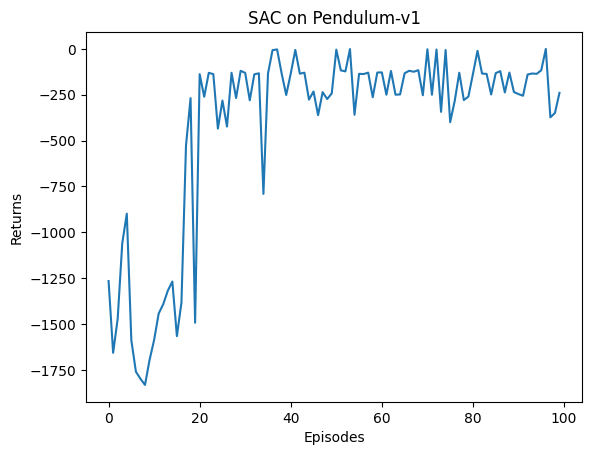

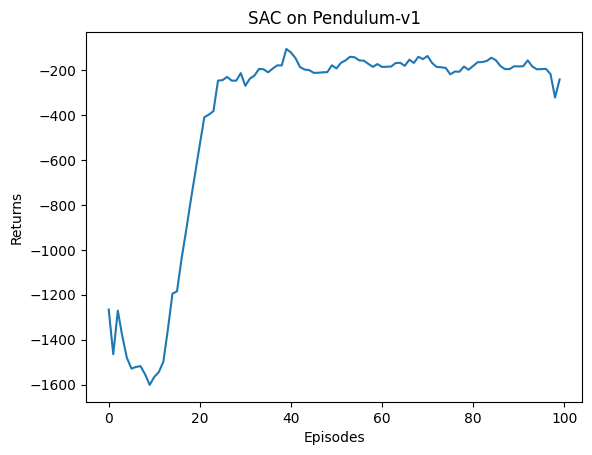

In [43]:
episodes_list = list(range(len(return_list)))
plt.plot(episodes_list, return_list)
plt.xlabel('Episodes')
plt.ylabel('Returns')
plt.title('SAC on {}'.format(env_name))
plt.show()

mv_return = rl_utils.moving_average(return_list, 9)
plt.plot(episodes_list, mv_return)
plt.xlabel('Episodes')
plt.ylabel('Returns')
plt.title('SAC on {}'.format(env_name))
plt.show()